In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

## 1. Dataset Overview

### 1.1 Loading the data and checking its size

**What this code does:**
- Loads `bank.csv` (separated by `;`) into a DataFrame `df`.
- Prints the number of rows and columns and the column names.

In [2]:
df = pd.read_csv("bank.csv", sep=";")
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (4521, 17)


In [3]:
print("Column names:")
print(df.columns.tolist())

Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


**Findings:**
- The dataset has 4,521 rows and 17 columns.
- Column names: age, job, marital, education, default, balance, housing, loan, contact, day, month, duration, campaign, pdays, previous, poutcome, y.
- The last column `y` looks like the target; the other 16 are candidate input features.

### 1.2 Previewing the data

**What this code does:**
- Shows the first five rows to see what the values look like.

In [4]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


**Findings:**
- The first rows show a mix of numbers (age, balance, duration) and text labels (job, marital, contact).
- Values such as `unknown` in `contact` and `poutcome`, and `-1` in `pdays`, already hint at missing information that is checked in Section 3.

### 1.3 Data types and non-null counts

**What this code does:**
- `df.info()` lists each column's data type and how many values are non-null.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        4521 non-null   int64
 1   job        4521 non-null   str  
 2   marital    4521 non-null   str  
 3   education  4521 non-null   str  
 4   default    4521 non-null   str  
 5   balance    4521 non-null   int64
 6   housing    4521 non-null   str  
 7   loan       4521 non-null   str  
 8   contact    4521 non-null   str  
 9   day        4521 non-null   int64
 10  month      4521 non-null   str  
 11  duration   4521 non-null   int64
 12  campaign   4521 non-null   int64
 13  pdays      4521 non-null   int64
 14  previous   4521 non-null   int64
 15  poutcome   4521 non-null   str  
 16  y          4521 non-null   str  
dtypes: int64(7), str(10)
memory usage: 600.6 KB


**Findings:**
- 7 numeric columns (`int64`): age, balance, day, duration, campaign, pdays, previous.
- 10 text columns (`object`): job, marital, education, default, housing, loan, contact, month, poutcome, y.
- All columns have 4,521 non-null values, so there are no NaN missing values.
- Missing information may still be hidden as the string `"unknown"`, which will be checked in Section 3.

## 2. Data Types and Feature Categorization

**What this code does:**
- Groups the 17 columns into numerical, categorical, temporal, identifier and target.
- Checks that every column is assigned exactly once.

In [6]:
numerical_cols = ["age", "balance", "duration", "campaign", "pdays", "previous"]
categorical_cols = ["job", "marital", "education", "default", "housing",
                    "loan", "contact", "poutcome"]
temporal_cols = ["day", "month"]
identifier_cols = []          
target_col = "y"

print("Numerical  :", numerical_cols)
print("Categorical:", categorical_cols)
print("Temporal   :", temporal_cols)
print("Identifier :", identifier_cols if identifier_cols else "None")
print("Target     :", target_col)

all_assigned = numerical_cols + categorical_cols + temporal_cols + identifier_cols + [target_col]
print("\nAll 17 columns covered:", sorted(all_assigned) == sorted(df.columns.tolist()))

Numerical  : ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']
Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'poutcome']
Temporal   : ['day', 'month']
Identifier : None
Target     : y

All 17 columns covered: True


**Findings:**
- **Numerical (6):** age, balance, duration, campaign, pdays, previous. These are continuous or count values, so they get summary statistics, histograms, and boxplots.
- **Categorical (8):** job, marital, education, default, housing, loan, contact, poutcome. These are text labels, so they get frequency counts and bar charts.
- **Temporal (2):** day (day of month) and month. They describe when the last contact happened. The dataset has no year, so they are treated as calendar categories.
- **Identifier:** none. There is no customer ID column, so nothing needs to be dropped.
- **Target:** `y` (yes/no), whether the client subscribed to a term deposit.
- The check returned `True`, so every column is assigned exactly once.

## 3. Missing Data and Quality Assessment

### 3.1 Missing values (NaN)

**What this code does:**
- Counts real missing values (`NaN`) in every column and prints only the columns that have any.

In [7]:
missing_count = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)

missing_df = pd.DataFrame({"missing_count": missing_count, "missing_%": missing_pct})
print(missing_df[missing_df["missing_count"] > 0])
print("\nTotal NaN values in dataset:", df.isnull().sum().sum())

Empty DataFrame
Columns: [missing_count, missing_%]
Index: []

Total NaN values in dataset: 0


**Findings:**
- The output table is empty and the total is 0, so the dataset has no NaN values.
- This agrees with `df.info()`, where every column had 4,521 non-null values.
- Missing information may still be hidden as the text `"unknown"`, which is checked next.

### 3.2 Hidden missing values ("unknown")

**What this code does:**
- Counts how often the text `"unknown"` appears in each column, because missing information can be hidden as a label.

In [8]:
unknown_count = (df == "unknown").sum()
unknown_pct = ((df == "unknown").mean() * 100).round(2)

unknown_df = pd.DataFrame({"unknown_count": unknown_count, "unknown_%": unknown_pct})
print(unknown_df[unknown_df["unknown_count"] > 0].sort_values("unknown_count", ascending=False))

           unknown_count  unknown_%
poutcome            3705      81.95
contact             1324      29.29
education            187       4.14
job                   38       0.84


**Findings:**

| Column | Unknown count | Unknown % |
|---|---|---|
| poutcome | 3,705 | 81.95% |
| contact | 1,324 | 29.29% |
| education | 187 | 4.14% |
| job | 38 | 0.84% |

- `poutcome` is "unknown" for about 82% of clients. This matches `pdays = -1` and `previous = 0`: these clients were never contacted in a previous campaign, so the value is not truly missing, it means "no previous outcome".
- `contact` has a large share (29%) of unknown contact types. This is real missing information.
- `education` (4.1%) and `job` (0.8%) have only small shares of unknown values.

**Handling decisions:**
- `poutcome`: keep, and treat "unknown" as its own category meaning "not previously contacted". Dropping 82% of rows or imputing would be misleading.
- `contact`: keep "unknown" as its own category. 29% is too large to impute reliably, and the "unknown" group may itself carry information.
- `education` and `job`: keep "unknown" as its own category for now. The shares are small, so it has little impact. Deleting rows would lose data, and imputing would add assumptions.
- No column is dropped.

### 3.3 Verifying the meaning of poutcome = "unknown"

**What this code does:**
- Cross-tabulates `poutcome == "unknown"` against `pdays == -1` to see whether they occur together.
- Checks that every client with `pdays = -1` also has `previous = 0`.

In [9]:
print(pd.crosstab(df["poutcome"] == "unknown", df["pdays"] == -1,
                  rownames=["poutcome is unknown"], colnames=["pdays is -1"]))

print("\nprevious == 0 when pdays == -1:", (df.loc[df["pdays"] == -1, "previous"] == 0).all())

pdays is -1          False  True 
poutcome is unknown              
False                  816      0
True                     0   3705

previous == 0 when pdays == -1: True


**Findings:**
- All 3,705 rows with poutcome "unknown" also have pdays = -1. The remaining 816 rows have neither. There are no mismatches.
- `previous == 0` whenever `pdays == -1` (True).
- Conclusion: "unknown" in `poutcome` means the client was not contacted in a previous campaign. It is a structural value, not random missing data, so it is kept as its own category.
- `pdays = -1` is a placeholder code, not a real number of days. It will be handled in preprocessing (e.g., create a flag `previously_contacted` and treat -1 separately).

### 3.4 Duplicate records

**What this code does:**
- Counts rows that are exact copies of another row.

In [10]:
dup_count = df.duplicated().sum()
print("Number of fully duplicated rows:", dup_count)
print("Percentage of duplicates: {:.2f}%".format(dup_count / len(df) * 100))

Number of fully duplicated rows: 0
Percentage of duplicates: 0.00%


**Findings:**
- Number of fully duplicated rows: 0 (0.00%).
- Decision: no action needed, since there are no duplicate records.

### 3.5 Invalid ranges in numeric columns

**What this code does:**
- Prints the minimum and maximum of each numeric column.
- Counts rows that break simple rules (day outside 1-31, age outside 18-100, negative balance, duration 0, campaign below 1, pdays below -1, previous below 0).

In [11]:
print("Min and max of each numeric column:")
print(df[["age", "balance", "day", "duration", "campaign", "pdays", "previous"]].agg(["min", "max"]).T)

print("\nRows with day outside 1-31:", ((df["day"] < 1) | (df["day"] > 31)).sum())
print("Rows with age < 18 or age > 100:", ((df["age"] < 18) | (df["age"] > 100)).sum())
print("Rows with negative balance:", (df["balance"] < 0).sum())
print("Rows with duration == 0:", (df["duration"] == 0).sum())
print("Rows with campaign < 1:", (df["campaign"] < 1).sum())
print("Rows with pdays < -1:", (df["pdays"] < -1).sum())
print("Rows with previous < 0:", (df["previous"] < 0).sum())

Min and max of each numeric column:
           min    max
age         19     87
balance  -3313  71188
day          1     31
duration     4   3025
campaign     1     50
pdays       -1    871
previous     0     25

Rows with day outside 1-31: 0
Rows with age < 18 or age > 100: 0
Rows with negative balance: 366
Rows with duration == 0: 0
Rows with campaign < 1: 0
Rows with pdays < -1: 0
Rows with previous < 0: 0


**Findings:**

| Column | Min | Max |
|---|---|---|
| age | 19 | 87 |
| balance | -3,313 | 71,188 |
| day | 1 | 31 |
| duration | 4 | 3,025 |
| campaign | 1 | 50 |
| pdays | -1 | 871 |
| previous | 0 | 25 |

- No rule is violated: 0 rows have `day` outside 1-31, `age` outside 18-100, `duration` = 0, `campaign` < 1, `pdays` < -1, or `previous` < 0.
- 366 rows (about 8.1%) have a negative `balance`. These are valid overdrawn accounts, so they are kept.
- `balance`, `duration`, `campaign`, and `previous` have very large maximum values compared with typical values. These are not errors, but possible outliers, which will be analyzed in Section 5.
- Decision: no rows are removed in this step.

### 3.6 Inconsistent formats in text columns

**What this code does:**
- For every text column, compares the number of unique values before and after removing spaces and lower-casing.
- Counts values with leading or trailing spaces.

In [12]:
text_cols = df.select_dtypes(include="object").columns

for col in text_cols:
    n_unique_raw = df[col].nunique()
    n_unique_clean = df[col].str.strip().str.lower().nunique()
    has_spaces = (df[col] != df[col].str.strip()).sum()
    print(f"{col:10s} unique values: {n_unique_raw:3d} | after strip+lower: {n_unique_clean:3d} | rows with extra spaces: {has_spaces}")

job        unique values:  12 | after strip+lower:  12 | rows with extra spaces: 0
marital    unique values:   3 | after strip+lower:   3 | rows with extra spaces: 0
education  unique values:   4 | after strip+lower:   4 | rows with extra spaces: 0
default    unique values:   2 | after strip+lower:   2 | rows with extra spaces: 0
housing    unique values:   2 | after strip+lower:   2 | rows with extra spaces: 0
loan       unique values:   2 | after strip+lower:   2 | rows with extra spaces: 0
contact    unique values:   3 | after strip+lower:   3 | rows with extra spaces: 0
month      unique values:  12 | after strip+lower:  12 | rows with extra spaces: 0
poutcome   unique values:   4 | after strip+lower:   4 | rows with extra spaces: 0
y          unique values:   2 | after strip+lower:   2 | rows with extra spaces: 0


**Findings:**
- Raw and cleaned unique counts are equal for all 10 text columns, so there is no mixed case or spacing problem.
- Rows with extra spaces: 0 in every column.
- Category counts: job (12), marital (3), education (4), default (2), housing (2), loan (2), contact (3), month (12), poutcome (4), y (2).
- Decision: no text cleaning is needed.

### Summary of Section 3
- No NaN values and no duplicate rows.
- Hidden missing values ("unknown") are in poutcome (81.95%), contact (29.29%), education (4.14%) and job (0.84%). All are kept as their own category.
- poutcome "unknown" means "not previously contacted" (matches pdays = -1 and previous = 0).
- No invalid ranges. 366 negative balances are valid overdrafts and are kept.
- Text formats are consistent.

## 4. Descriptive Statistics

### 4.1 Summary statistics for numerical variables

**What this code does:**
- Computes count, mean, median, standard deviation, min, max and skewness for the six numeric columns.

In [13]:
num_cols = ["age", "balance", "duration", "campaign", "pdays", "previous"]

summary = df[num_cols].describe().T
summary["median"] = df[num_cols].median()
summary["skew"] = df[num_cols].skew()

print(summary[["count", "mean", "median", "std", "min", "max", "skew"]].round(2))

           count     mean  median      std     min      max  skew
age       4521.0    41.17    39.0    10.58    19.0     87.0  0.70
balance   4521.0  1422.66   444.0  3009.64 -3313.0  71188.0  6.60
duration  4521.0   263.96   185.0   259.86     4.0   3025.0  2.77
campaign  4521.0     2.79     2.0     3.11     1.0     50.0  4.74
pdays     4521.0    39.77    -1.0   100.12    -1.0    871.0  2.72
previous  4521.0     0.54     0.0     1.69     0.0     25.0  5.88


**Findings:**

| Column | Mean | Median | Std | Skew |
|---|---|---|---|---|
| age | 41.17 | 39 | 10.58 | 0.70 |
| balance | 1422.66 | 444 | 3009.64 | 6.60 |
| duration | 263.96 | 185 | 259.86 | 2.77 |
| campaign | 2.79 | 2 | 3.11 | 4.74 |
| pdays | 39.77 | -1 | 100.12 | 2.72 |
| previous | 0.54 | 0 | 1.69 | 5.88 |

- `age` is roughly symmetric: mean (41.2) is close to median (39), with mild right skew (0.70).
- `balance` is extremely right-skewed: the mean (1,423) is more than three times the median (444), and the std (3,010) is twice the mean. A few very large balances pull the mean up.
- `duration` and `campaign` are also strongly right-skewed (mean above median, skew 2.77 and 4.74). Most calls are short and most clients are contacted few times, with a small number of extreme cases (duration up to 3,025 seconds, campaign up to 50 contacts).
- `previous` has a median of 0 and skew of 5.88, because most clients were never contacted before.
- `pdays` has a median of -1, which confirms that more than half of the clients have the placeholder value. Its mean (39.77) is therefore not meaningful as a number of days.
- Because of the heavy skew, capping followed by a log transform is applied to the skewed columns in Section 7 (using the training data only).

### 4.2 Distributions of numerical variables

**What this code does:**
- Draws a histogram with a smoothed density line for each numeric column.

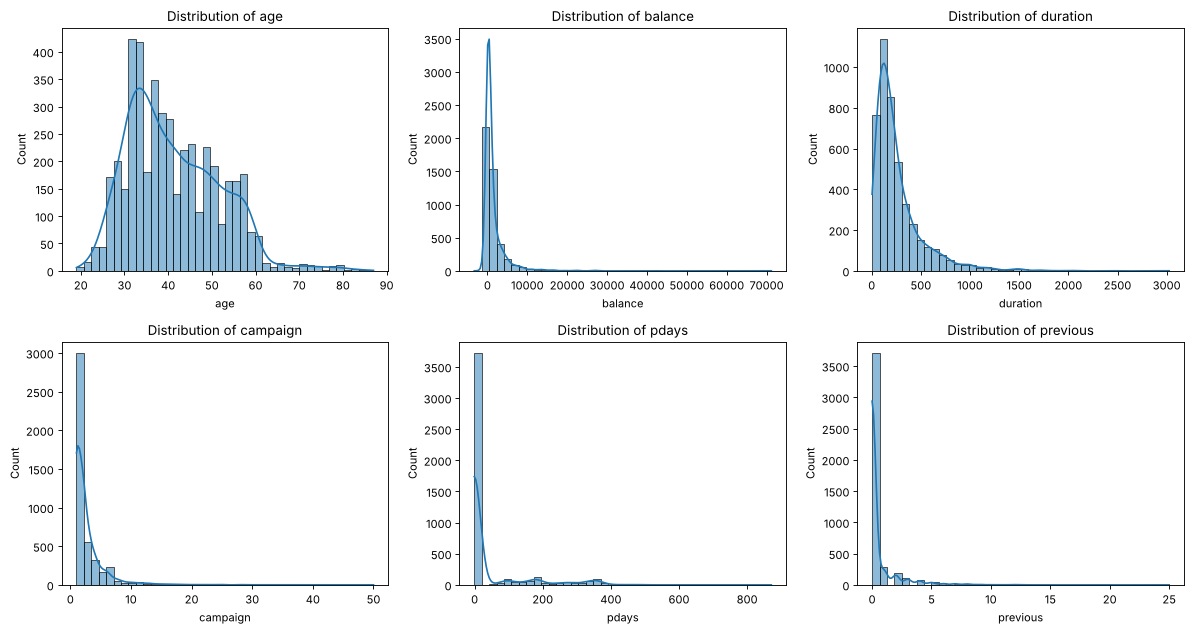

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], bins=40, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

**Findings:**
- `age`: roughly bell-shaped, peaking around 30-35, with a mild right tail up to the late 80s. It is the only numeric column close to symmetric.
- `balance`: almost all clients are concentrated near zero, with a very long right tail up to about 71,000. A few large balances stretch the x-axis.
- `duration`: right-skewed. Most calls are short (peak around 100-200 seconds), with a thin tail beyond 1,500 seconds.
- `campaign`: most clients were contacted 1-3 times, with a long tail up to 50 contacts.
- `previous`: a large spike at 0 and a long tail up to 25.
- `pdays`: a huge spike at -1 (the "not previously contacted" placeholder, about 3,705 rows). The remaining values are spread between roughly 50 and 400 days, with a few beyond 800.
- These shapes confirm the skewness values from Section 4.1. `balance`, `campaign`, `previous` and `duration` are good candidates for a log transform or capping, and `pdays` needs the placeholder handled separately.

### 4.3 Frequency counts for categorical variables

**What this code does:**
- Prints the count and percentage of every category for job, marital, education and default (first group).

In [15]:
cat_cols_1 = ["job", "marital", "education", "default"]

for col in cat_cols_1:
    counts = df[col].value_counts()
    pct = (df[col].value_counts(normalize=True) * 100).round(2)
    print(f"--- {col} ---")
    print(pd.DataFrame({"count": counts, "%": pct}))
    print()

--- job ---
               count      %
job                        
management       969  21.43
blue-collar      946  20.92
technician       768  16.99
admin.           478  10.57
services         417   9.22
retired          230   5.09
self-employed    183   4.05
entrepreneur     168   3.72
unemployed       128   2.83
housemaid        112   2.48
student           84   1.86
unknown           38   0.84

--- marital ---
          count      %
marital               
married    2797  61.87
single     1196  26.45
divorced    528  11.68

--- education ---
           count      %
education              
secondary   2306  51.01
tertiary    1350  29.86
primary      678  15.00
unknown      187   4.14

--- default ---
         count      %
default              
no        4445  98.32
yes         76   1.68



**Findings:**
- `job`: 12 categories. The most common are management (21.43%), blue-collar (20.92%) and technician (16.99%), which together cover about 59% of clients. The smallest are student (1.86%) and "unknown" (0.84%).
- `marital`: married clients dominate (61.87%), followed by single (26.45%) and divorced (11.68%).
- `education`: secondary is the largest group (51.01%), then tertiary (29.86%) and primary (15.00%). "unknown" is only 4.14%.
- `default`: extremely imbalanced. 98.32% of clients have no credit default and only 76 clients (1.68%) do. This column carries little information on its own, but it will be kept and its relationship with the target checked in Section 6.

**What this code does (second group):**
- Prints the same counts and percentages for housing, loan, contact and poutcome.

In [16]:
cat_cols_2 = ["housing", "loan", "contact", "poutcome"]

for col in cat_cols_2:
    counts = df[col].value_counts()
    pct = (df[col].value_counts(normalize=True) * 100).round(2)
    print(f"--- {col} ---")
    print(pd.DataFrame({"count": counts, "%": pct}))
    print()

--- housing ---
         count     %
housing             
yes       2559  56.6
no        1962  43.4

--- loan ---
      count      %
loan              
no     3830  84.72
yes     691  15.28

--- contact ---
           count      %
contact                
cellular    2896  64.06
unknown     1324  29.29
telephone    301   6.66

--- poutcome ---
          count      %
poutcome              
unknown    3705  81.95
failure     490  10.84
other       197   4.36
success     129   2.85



**Findings:**
- `housing`: fairly balanced. 56.6% of clients have a housing loan and 43.4% do not.
- `loan`: imbalanced. 84.72% have no personal loan and 15.28% do.
- `contact`: cellular is the main channel (64.06%), followed by "unknown" (29.29%) and telephone (6.66%). The large "unknown" group was discussed in Section 3.
- `poutcome`: "unknown" dominates (81.95%, clients not previously contacted). Among those previously contacted, failure is 10.84%, other 4.36% and success only 2.85% (129 clients).
- The small "success" group may still be an informative predictor of the target, which will be checked in Section 6.

### 4.4 Contacts by month and by day

**What this code does:**
- Counts contacts per month (in calendar order) and draws a bar chart.
- Draws a histogram of the day of the month.

month
jan     148
feb     222
mar      49
apr     293
may    1398
jun     531
jul     706
aug     633
sep      52
oct      80
nov     389
dec      20
Name: count, dtype: int64


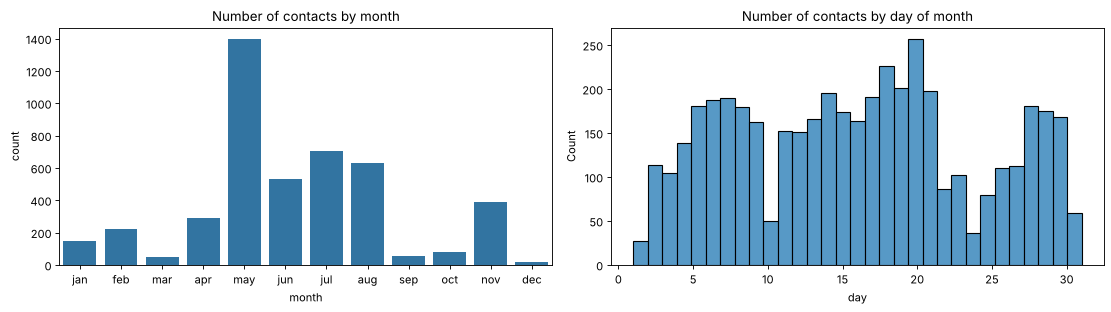

In [17]:
month_order = ["jan", "feb", "mar", "apr", "may", "jun",
               "jul", "aug", "sep", "oct", "nov", "dec"]

month_counts = df["month"].value_counts().reindex(month_order)
print(month_counts)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.barplot(x=month_counts.index, y=month_counts.values, ax=axes[0])
axes[0].set_title("Number of contacts by month")
axes[0].set_xlabel("month")
axes[0].set_ylabel("count")

sns.histplot(df["day"], bins=31, ax=axes[1])
axes[1].set_title("Number of contacts by day of month")
axes[1].set_xlabel("day")

plt.tight_layout()
plt.show()

**Findings:**
- `month`: contacts are heavily concentrated in May (about 1,400, roughly 30% of all records), followed by July, August and June. March, September, October and December have very few contacts (under about 100 each), so the seasonality is strong and the data is not evenly spread over the year.
- `day`: contacts are spread across the whole month, with noticeable dips around days 1, 10, 22-23 and 31. These dips are likely weekends and month-end (e.g., calls are made less on non-working days). Peaks occur around days 18-20.
- Because the months are so uneven, any month-related pattern with the target must be interpreted with care (small months give unstable percentages). The relationship with `y` is checked in Section 6.

### Summary of Section 4
- `age` is roughly symmetric. `balance`, `duration`, `campaign`, `previous` and `pdays` are strongly right-skewed.
- `default` (98.3% "no") and `poutcome` (82% "unknown") are highly imbalanced categories.
- `job`, `marital`, `education`, `housing` and `contact` have usable spread across categories.
- Contacts are concentrated in May and in the middle of the month.

## 5. Outliers and Data Quality Checks

### 5.1 Boxplots of numerical variables

**What this code does:**
- Draws a boxplot for each numeric column. Points beyond the whiskers are potential outliers.

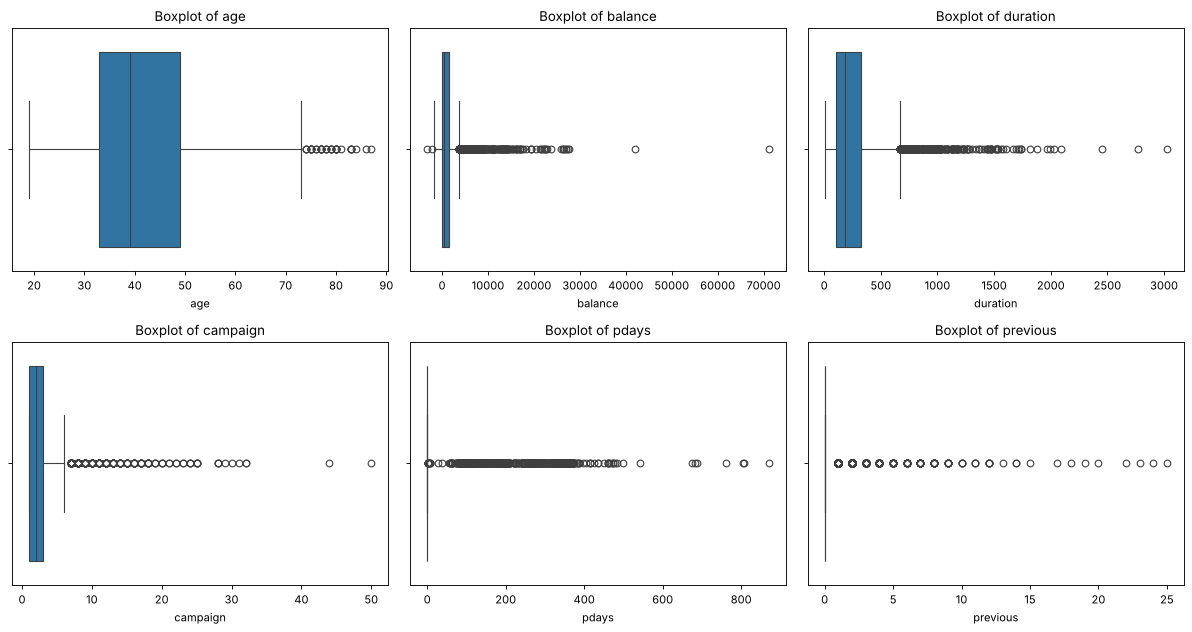

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

**Findings:**
- `age`: only a small number of points above the upper whisker (about 73 years), reaching 87. These are older but realistic clients.
- `balance`: a very long trail of high values, with two extreme points near 42,000 and 71,000. A few negative values also fall below the lower whisker.
- `duration`: many points beyond about 650 seconds, with three extreme calls above 2,400 seconds (up to 3,025).
- `campaign`: values above about 6 contacts are flagged, with extreme points at 44 and 50.
- `pdays` and `previous`: the box collapses to a line (at -1 and 0), because most clients were never previously contacted. Nearly all other values are therefore flagged, which is a structural effect of the placeholder, not a sign of bad data.
- None of the flagged values is impossible, so they are treated as genuine but extreme observations.

### 5.2 IQR-based outlier counts

**What this code does:**
- Computes the IQR bounds (Q1 - 1.5 x IQR, Q3 + 1.5 x IQR) for age, balance, duration and campaign and counts the values outside them.
- Summarizes `pdays` and `previous` only for clients who were previously contacted.

In [19]:
rows = []
for col in ["age", "balance", "duration", "campaign"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    rows.append([col, Q1, Q3, round(lower, 1), round(upper, 1), n_out, round(n_out / len(df) * 100, 2)])

outlier_df = pd.DataFrame(rows, columns=["column", "Q1", "Q3", "lower_bound", "upper_bound", "n_outliers", "%_outliers"])
print(outlier_df)

# pdays and previous: look only at clients who were previously contacted
prev = df[df["pdays"] != -1]
print("\nPreviously contacted clients:", len(prev))
print(prev[["pdays", "previous"]].describe().round(2))

     column     Q1      Q3  lower_bound  upper_bound  n_outliers  %_outliers
0       age   33.0    49.0          9.0         73.0          38        0.84
1   balance   69.0  1480.0      -2047.5       3596.5         506       11.19
2  duration  104.0   329.0       -233.5        666.5         330        7.30
3  campaign    1.0     3.0         -2.0          6.0         318        7.03

Previously contacted clients: 816
        pdays  previous
count  816.00    816.00
mean   224.87      3.01
std    117.20      2.91
min      1.00      1.00
25%    136.00      1.00
50%    189.00      2.00
75%    330.00      4.00
max    871.00     25.00


**Findings:**

| Column | Lower bound | Upper bound | Outliers | % |
|---|---|---|---|---|
| age | 9.0 | 73.0 | 38 | 0.84 |
| balance | -2047.5 | 3596.5 | 506 | 11.19 |
| duration | -233.5 | 666.5 | 330 | 7.30 |
| campaign | -2.0 | 6.0 | 318 | 7.03 |

- `balance` has the most outliers (11.19%), then `duration` (7.30%) and `campaign` (7.03%). `age` has very few (0.84%).
- Among the 816 previously contacted clients, `pdays` has a median of 189 days (range 1 to 871) and `previous` has a median of 2 contacts (range 1 to 25). These values are plausible, so no special action is needed beyond the placeholder handling.
- The lower bounds for duration and campaign are negative, so no low-side outliers exist for them. For `balance`, the lower bound (-2,047.5) flags only a few overdrawn accounts.

### 5.3 Outlier handling decision

**What this code does:**
- Creates a 0/1 helper column `y_bin` (1 = subscribed).
- Compares the subscription rate of outliers and non-outliers for balance, duration and campaign, to decide whether outliers should be removed.

In [20]:
df["y_bin"] = (df["y"] == "yes").astype(int)

for col, upper in [("balance", 3596.5), ("duration", 666.5), ("campaign", 6)]:
    is_out = df[col] > upper
    print(f"{col:9s} | outliers: {is_out.sum():4d} -> subscribe rate {df.loc[is_out, 'y_bin'].mean()*100:5.2f}%"
          f" | non-outliers: {(~is_out).sum():4d} -> subscribe rate {df.loc[~is_out, 'y_bin'].mean()*100:5.2f}%")

balance   | outliers:  504 -> subscribe rate 14.29% | non-outliers: 4017 -> subscribe rate 11.18%
duration  | outliers:  330 -> subscribe rate 50.00% | non-outliers: 4191 -> subscribe rate  8.49%
campaign  | outliers:  318 -> subscribe rate  5.66% | non-outliers: 4203 -> subscribe rate 11.97%


**Findings:**

| Column | Outliers (above upper bound) | Subscribe rate (outliers) | Subscribe rate (others) |
|---|---|---|---|
| balance | 504 | 14.29% | 11.18% |
| duration | 330 | 50.00% | 8.49% |
| campaign | 318 | 5.66% | 11.97% |

- `duration` outliers subscribe at a rate about 6 times higher than the rest, so they carry strong signal.
- `balance` outliers subscribe slightly more, and `campaign` outliers subscribe about half as often. Both groups behave differently, so they also carry information.
- The upper-side counts (504 for balance) are slightly lower than the IQR totals (506) because 2 balance outliers are below the lower bound.

### 5.4 Preview of capping

**What this code does:**
- Previews capping at the 1st and 99th percentiles and prints the skewness before and after.
- This is only a preview on the whole dataset to choose a method. The thresholds used for modeling are learned from the training set only in Section 7.

In [21]:
for col in ["balance", "duration", "campaign"]:
    low, high = df[col].quantile(0.01), df[col].quantile(0.99)
    capped = df[col].clip(lower=low, upper=high)
    print(f"{col:9s} | 1st pct: {low:8.1f} | 99th pct: {high:8.1f} | "
          f"skew before: {df[col].skew():5.2f} -> after: {capped.skew():5.2f}")

balance   | 1st pct:   -671.4 | 99th pct:  14194.6 | skew before:  6.60 -> after:  3.10
duration  | 1st pct:     10.2 | 99th pct:   1259.0 | skew before:  2.77 -> after:  1.96
campaign  | 1st pct:      1.0 | 99th pct:     16.0 | skew before:  4.74 -> after:  2.79


**Findings:**

| Column | 1st pct | 99th pct | Skew before | Skew after |
|---|---|---|---|---|
| balance | -671.4 | 14,194.6 | 6.60 | 3.10 |
| duration | 10.2 | 1,259.0 | 2.77 | 1.96 |
| campaign | 1.0 | 16.0 | 4.74 | 2.79 |

- Capping reduces the skew substantially for all three columns, most of all for `balance`, whose extreme values (up to 71,188) had the biggest pull.
- Skew is still above 1 for all three after capping, so in Section 7 a `log1p` transform is applied on top of capping for the features that are kept (`balance` and `campaign`). `duration` is not used as a model feature (leakage risk, see Section 6.2), so it is not transformed.
- The capped values (balance up to about 14,195, campaign up to 16 contacts) are still realistic, so little real information is lost.
- Because this preview uses all rows, the final thresholds are re-learned from the training rows only in Section 7.

## 6. Target Variable Exploration

### 6.1 Distribution of the target variable `y`

**What this code does:**
- Counts and shows the percentage of "no" and "yes", computes the imbalance ratio and draws a bar chart.

     count      %
y                
no    4000  88.48
yes    521  11.52

Imbalance ratio (no : yes) = 7.7 : 1


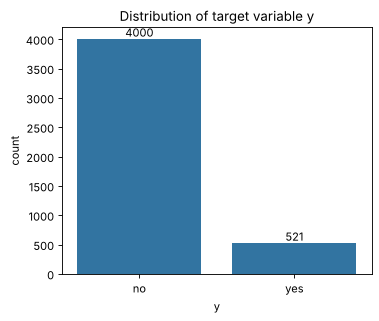

In [22]:
target_counts = df["y"].value_counts()
target_pct = (df["y"].value_counts(normalize=True) * 100).round(2)
print(pd.DataFrame({"count": target_counts, "%": target_pct}))

print("\nImbalance ratio (no : yes) = {:.1f} : 1".format(target_counts["no"] / target_counts["yes"]))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x="y", data=df, order=["no", "yes"], ax=ax)
ax.set_title("Distribution of target variable y")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.show()

**Findings:**
- Class split: no = 4,000 (88.48%), yes = 521 (11.52%).
- Imbalance ratio: 7.7 : 1.
- This is a **moderately imbalanced binary classification** problem. A model that always predicts "no" would reach 88.48% accuracy without finding a single subscriber, so accuracy alone is misleading.
- Modeling implications: use **stratified** train/test splits, evaluate with precision, recall, F1 and ROC-AUC (or PR-AUC), and consider class weights or resampling (e.g., SMOTE on the training set only).
- Business relevance: the AI task is to identify the clients likely to subscribe, so catching the minority "yes" class (recall) matters more than overall accuracy.

### 6.2 Numerical features vs the target

**What this code does:**
- Prints the mean and median of each numeric feature for "no" and "yes" clients.
- Draws a boxplot of each numeric feature split by `y`.

y                    no     yes
age      mean      41.0    42.5
         median    39.0    40.0
balance  mean    1403.2  1572.0
         median   419.5   710.0
duration mean     226.3   552.7
         median   167.0   442.0
campaign mean       2.9     2.3
         median     2.0     2.0
pdays    mean      36.0    68.6
         median    -1.0    -1.0
previous mean       0.5     1.1
         median     0.0     0.0


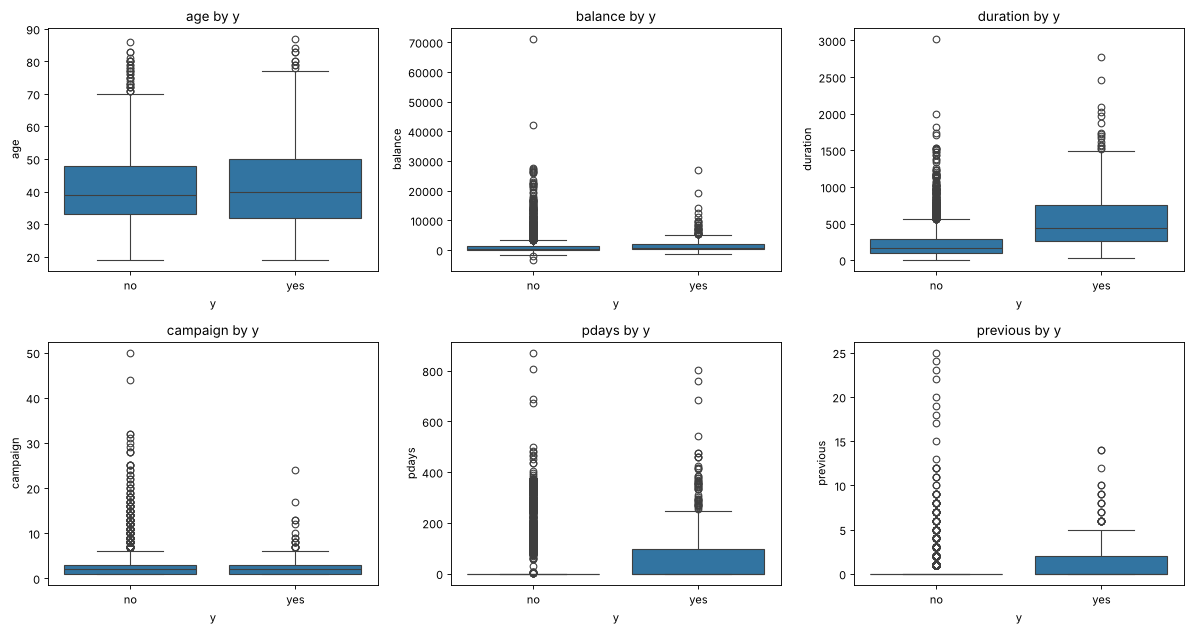

In [23]:
print(df.groupby("y")[num_cols].agg(["mean", "median"]).round(1).T)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    sns.boxplot(x="y", y=col, data=df, order=["no", "yes"], ax=ax)
    ax.set_title(f"{col} by y")

plt.tight_layout()
plt.show()

**Findings:**

| Feature | Mean (no) | Mean (yes) | Median (no) | Median (yes) |
|---|---|---|---|---|
| age | 41.0 | 42.5 | 39 | 40 |
| balance | 1403.2 | 1572.0 | 419.5 | 710 |
| duration | 226.3 | 552.7 | 167 | 442 |
| campaign | 2.9 | 2.3 | 2 | 2 |
| pdays | 36.0 | 68.6 | -1 | -1 |
| previous | 0.5 | 1.1 | 0 | 0 |

- **`duration`** is the most informative numeric feature. Subscribers have a much longer call (median 442 s vs 167 s), and their boxplot sits clearly higher. Remember it is only known after the call, so it is a data leakage risk for a real predictive model.
- **`balance`** shows a moderate difference (median 710 vs 420), so it has some predictive value.
- **`pdays` and `previous`** have higher means for "yes" clients, but identical medians because most clients were never contacted before. The signal comes from the previously contacted group, so the `previously_contacted` flag will capture it better than the raw values.
- **`age`** is weak: the distributions overlap almost completely (median 40 vs 39).
- **`campaign`** is weak to moderate: same median (2), but "no" clients have a longer tail of many contacts. Many contacts do not lead to more subscriptions.

### 6.3 Subscription rate by categorical feature

**What this code does:**
- For every categorical column, prints the number of clients and the subscription rate (%) of each category.

In [24]:
for col in ["job", "marital", "education", "default", "housing", "loan", "contact", "poutcome"]:
    rate = (df.groupby(col)["y_bin"].agg(["count", "mean"])
              .assign(mean=lambda d: (d["mean"] * 100).round(2))
              .rename(columns={"mean": "subscribe_%"})
              .sort_values("subscribe_%", ascending=False))
    print(f"--- {col} ---")
    print(rate)
    print()

--- job ---
               count  subscribe_%
job                              
retired          230        23.48
student           84        22.62
unknown           38        18.42
management       969        13.52
housemaid        112        12.50
admin.           478        12.13
self-employed    183        10.93
technician       768        10.81
unemployed       128        10.16
services         417         9.11
entrepreneur     168         8.93
blue-collar      946         7.29

--- marital ---
          count  subscribe_%
marital                     
divorced    528        14.58
single     1196        13.96
married    2797         9.90

--- education ---
           count  subscribe_%
education                    
tertiary    1350        14.30
secondary   2306        10.62
unknown      187        10.16
primary      678         9.44

--- default ---
         count  subscribe_%
default                    
yes         76        11.84
no        4445        11.52

--- housing ---
     

**Findings:**

| Feature | Highest rate | Lowest rate | Informative? |
|---|---|---|---|
| poutcome | success 64.34% | unknown 9.10% | Very strong |
| contact | telephone 14.62%, cellular 14.36% | unknown 4.61% | Strong |
| job | retired 23.48%, student 22.62% | blue-collar 7.29% | Moderate to strong |
| housing | no 15.34% | yes 8.60% | Moderate |
| loan | no 12.48% | yes 6.22% | Moderate |
| marital | divorced 14.58%, single 13.96% | married 9.90% | Moderate |
| education | tertiary 14.30% | primary 9.44% | Weak to moderate |
| default | yes 11.84% | no 11.52% | None |

- `poutcome` is the most informative categorical feature. Clients with a previous successful campaign subscribe at about 5.6 times the overall rate, even though the group is small (129 clients).
- `contact = unknown` has a much lower rate (4.61%), so the "unknown" category itself carries information. This supports keeping it as its own category instead of imputing it.
- `job`: retired and student clients subscribe most, blue-collar least. The "unknown" job group (18.42%) has only 38 clients, so its rate is unstable.
- `housing` and `loan`: clients without a housing loan or personal loan subscribe more, possibly because they have fewer financial commitments.
- `default` is nearly useless (11.84% vs 11.52%, and only 76 "yes" clients), so it is a candidate to drop.
- `education` shows only a small difference across categories.

### 6.4 Subscription rate by contact month

**What this code does:**
- Prints contacts and subscription rate per month and draws a bar chart with the overall rate as a dashed line.

       count  subscribe_%
month                    
jan      148        10.81
feb      222        17.12
mar       49        42.86
apr      293        19.11
may     1398         6.65
jun      531        10.36
jul      706         8.64
aug      633        12.48
sep       52        32.69
oct       80        46.25
nov      389        10.03
dec       20        45.00


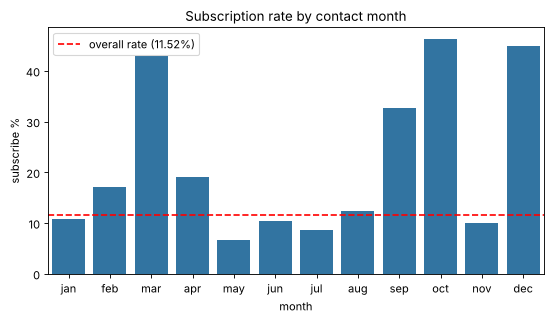

In [25]:
month_order = ["jan", "feb", "mar", "apr", "may", "jun",
               "jul", "aug", "sep", "oct", "nov", "dec"]

month_rate = (df.groupby("month")["y_bin"].agg(["count", "mean"])
                .reindex(month_order))
month_rate["subscribe_%"] = (month_rate["mean"] * 100).round(2)
print(month_rate[["count", "subscribe_%"]])

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=month_rate.index, y=month_rate["subscribe_%"], ax=ax)
ax.axhline(df["y_bin"].mean() * 100, color="red", linestyle="--", label="overall rate (11.52%)")
ax.set_title("Subscription rate by contact month")
ax.set_ylabel("subscribe %")
ax.legend()
plt.show()

**Findings:**

| Month | Contacts | Subscribe % |
|---|---|---|
| mar | 49 | 42.86 |
| sep | 52 | 32.69 |
| oct | 80 | 46.25 |
| dec | 20 | 45.00 |
| may | 1,398 | 6.65 |
| jul | 706 | 8.64 |

- The four months with the highest rates (March 42.86%, September 32.69%, October 46.25%, December 45.00%) are also the months with the fewest contacts (20 to 80 each). Their rates are based on small samples, so they are unstable.
- May, the busiest month (1,398 contacts, about 31% of the data), has the lowest rate (6.65%), well below the overall 11.52%. July (8.64%) and June (10.36%) are also below average.
- February (17.12%) and April (19.11%) are above average with moderate sample sizes, so they are more reliable.
- `month` is clearly informative: the rate ranges from 6.65% to 46.25%. A possible explanation is that the bank contacted many clients in May with a broad, less targeted campaign, and fewer, more selective clients in the other months.
- Decision: keep `month` as a categorical feature. One-hot encoding is appropriate, since the months are not related linearly to the target.

### 6.5 Correlation analysis

**What this code does:**
- Computes the Pearson correlation between the numeric features and the target and shows it as a heatmap.

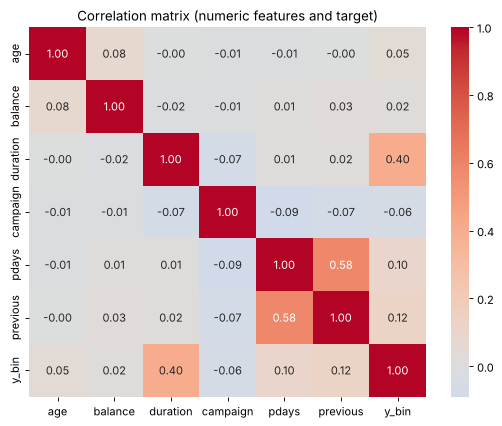

In [26]:
corr_cols = ["age", "balance", "duration", "campaign", "pdays", "previous", "y_bin"]
corr = df[corr_cols].corr().round(2)

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation matrix (numeric features and target)")
plt.show()

**Findings:**

| Feature | Correlation with y |
|---|---|
| duration | 0.40 |
| previous | 0.12 |
| pdays | 0.10 |
| age | 0.05 |
| balance | 0.02 |
| campaign | -0.06 |

- `duration` is the only numeric feature with a moderate linear relationship with the target (r = 0.40), which matches the boxplots in Section 6.2.
- `previous` and `pdays` are weakly positive (0.12 and 0.10). `age`, `balance` and `campaign` are very weak (|r| <= 0.06).
- `pdays` and `previous` are correlated with each other (r = 0.58), because both describe the earlier campaign. This is the only notable redundancy. All other pairs are below 0.10, so there is no serious multicollinearity.
- Pearson correlation only measures linear relationships. `balance` and `campaign` showed differences in subscription rate for their outliers (Section 5.3), so weak correlation does not mean they are useless. Tree-based models can capture non-linear effects.

### Summary of Section 6
- Target `y`: 88.48% "no", 11.52% "yes" (7.7 : 1), moderately imbalanced.
- Most informative features: `duration` (numeric, but a leakage risk), `poutcome`, `contact`, `month`, `job`.
- Moderately informative: `housing`, `loan`, `marital`, `education`, `balance`, `previous`.
- Weak or noisy: `default` (11.84% vs 11.52%), `age`, `campaign`.

## 7. Data Preprocessing

**Order of the steps.** To avoid data leakage, every value that is *learned from data* (capping thresholds, log shift, scaler mean and standard deviation) is learned from the **training set only** and then applied to the test set. The order is: feature engineering and encoding (no learned values) -> train/test split -> capping -> log transform -> scaling.

### 7.1 Feature engineering, target and encoding

**What this code does:**
- Creates `previously_contacted` (1 if `pdays` is not -1) and replaces the -1 placeholder in `pdays` with 0.
- Encodes the target as 0/1.
- Drops `default` (no relation to the target), `duration` (only known after the call, leakage risk) and the helper column `y_bin`.
- One-hot encodes the categorical columns with `drop_first=True`.
- No capping or scaling is done here, because those steps must learn from the training set only.

In [27]:
df_model = df.copy()

df_model["previously_contacted"] = 0
df_model.loc[df_model["pdays"] != -1, "previously_contacted"] = 1
df_model.loc[df_model["pdays"] == -1, "pdays"] = 0

y = df_model["y"].map({"no": 0, "yes": 1})
X = df_model.drop(columns=["y", "y_bin", "default", "duration"])
X = pd.get_dummies(X, drop_first=True)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nTarget values:")
print(y.value_counts())

X shape: (4521, 41)
y shape: (4521,)

Target values:
y
0    4000
1     521
Name: count, dtype: int64


**Findings:**
- X has 4,521 rows and 41 columns after encoding: 7 numeric/flag columns (age, balance, day, campaign, pdays, previous, previously_contacted) plus 34 one-hot columns.
- The target counts are unchanged: 4,000 for 0 and 521 for 1.
- One-hot encoding only reads the category labels, not the target or any statistic, so doing it before the split does not leak information.

### 7.2 Stratified train/test split

**What this code does:**
- Splits the data 80/20 with `stratify=y` so both parts keep the same share of "yes".
- From this point on, the test set is only used to *apply* what was learned on the training set.

In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("\nTarget rate in train: {:.2f}%".format(y_train.mean() * 100))
print("Target rate in test : {:.2f}%".format(y_test.mean() * 100))

X_train shape: (3616, 41)
X_test shape: (905, 41)

Target rate in train: 11.53%
Target rate in test : 11.49%


**Findings:**
- Train set: 3,616 rows. Test set: 905 rows (41 features each).
- Subscription rate: train 11.53%, test 11.49%, both very close to the overall 11.52%, so the class balance is preserved in both sets.

### 7.3 Capping outliers (thresholds learned from the training set only)

**What this code does:**
- Learns the capping thresholds from `X_train` only: the 99th percentile of `balance` and of `campaign`.
- Applies the same thresholds to both the training and the test set (`clip`).
- For comparison, prints the thresholds that the whole dataset would have given (not used).
- `duration` is not in `X`, so it needs no capping.

In [29]:
X_train = X_train.copy()
X_test = X_test.copy()

bal_high = X_train["balance"].quantile(0.99)
camp_high = X_train["campaign"].quantile(0.99)

print("Thresholds learned from TRAIN : balance max {:.1f}, campaign max {:.0f}".format(bal_high, camp_high))
print("Thresholds from FULL data (not used): balance max {:.1f}, campaign max {:.0f}".format(
    X["balance"].quantile(0.99), X["campaign"].quantile(0.99)))

print("\nTrain skew before capping:", X_train[["balance", "campaign"]].skew().round(2).to_dict())

for data in [X_train, X_test]:
    data["balance"] = data["balance"].clip(upper=bal_high)
    data["campaign"] = data["campaign"].clip(upper=camp_high)

print("Train skew after capping :", X_train[["balance", "campaign"]].skew().round(2).to_dict())

Thresholds learned from TRAIN : balance max 13704.7, campaign max 17
Thresholds from FULL data (not used): balance max 14194.6, campaign max 16

Train skew before capping: {'balance': 4.66, 'campaign': 4.91}
Train skew after capping : {'balance': 3.0, 'campaign': 2.9}


**Findings:**
- Thresholds learned from the training set: `balance` capped at 13,704.7 and `campaign` at 17. The full dataset would have given 14,194.6 and 16, so the thresholds differ, which shows why they must not be taken from the whole data.
- Training skew after capping: balance 4.66 -> 3.00, campaign 4.91 -> 2.90.
- The test set is capped with the *training* thresholds. Test values above them are cut down to them; the test set does not influence any threshold.

### 7.4 Log transform of the skewed features

**What this code does:**
- Applies `np.log1p` (log of 1 + x) to `balance` and `campaign`, the skewed features that are still skewed after capping.
- `balance` can be negative (overdrafts), and `log1p` needs values above -1, so `balance` uses a signed log: `sign(x) * log1p(|x|)`. Positive values are compressed like a normal log, and negative values stay negative.
- This transform has no learned parameters, so nothing is taken from the test set. The capping thresholds it works on come from the training set.
- Prints the skewness of the training set before and after.

In [30]:
print("Train skew before log:", X_train[["balance", "campaign"]].skew().round(2).to_dict())

for data in [X_train, X_test]:
    data["balance"] = np.sign(data["balance"]) * np.log1p(data["balance"].abs())
    data["campaign"] = np.log1p(data["campaign"])

print("Train skew after log :", X_train[["balance", "campaign"]].skew().round(2).to_dict())

Train skew before log: {'balance': 3.0, 'campaign': 2.9}
Train skew after log : {'balance': -1.57, 'campaign': 1.17}


**Findings:**
- Training skew after the log transform: balance 3.00 -> -1.57, campaign 2.90 -> 1.17.
- `campaign` is now close to symmetric (1.17). `balance` has a mild left tail (-1.57) because small and negative balances are stretched, but its absolute skew is about half of what it was, so the transform helps.
- The log transform is monotonic, so tree-based models are not affected by it. Linear and distance-based models benefit from the smaller skew.
- `previous` (skew 5.88) is not transformed. Its information is mainly carried by the `previously_contacted` flag, and `pdays` was already handled with the same flag.

### 7.5 Scaling numeric features (fitted on the training set only)

**What this code does:**
- Fits a `StandardScaler` on the training set (it learns the mean and standard deviation of each column) and transforms both the training and the test set with it.
- The unscaled versions (`X_train`, `X_test`) are kept for tree-based models.

In [31]:
from sklearn.preprocessing import StandardScaler

scale_cols = ["age", "balance", "day", "campaign", "pdays", "previous"]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

print("Train (should be mean 0, std 1):")
print(X_train_scaled[scale_cols].describe().loc[["mean", "std"]].round(2))
print("\nTest (close to, but not exactly, 0 and 1):")
print(X_test_scaled[scale_cols].describe().loc[["mean", "std"]].round(2))

Train (should be mean 0, std 1):
      age  balance  day  campaign  pdays  previous
mean -0.0      0.0  0.0      -0.0   -0.0       0.0
std   1.0      1.0  1.0       1.0    1.0       1.0

Test (close to, but not exactly, 0 and 1):
       age  balance   day  campaign  pdays  previous
mean  0.06     0.04 -0.08      0.01  -0.02     -0.01
std   1.05     0.94  1.02      1.00   1.00      1.11


**Findings:**
- In the training set, each scaled column has mean 0 and standard deviation 1. The `-0.0` values are rounding artifacts.
- In the test set the means and standard deviations are close to, but not exactly, 0 and 1 (for example age 0.06 / 1.05). This is expected and correct: the scaler used the training statistics only, so the test set is not forced to look like the training set.
- The data is now ready for modeling.

## 8. Summary of EDA Findings and Readiness for Modeling

### 8.1 Key EDA findings
- **Dataset:** 4,521 clients, 16 input features and the target `y` (term deposit subscription: yes/no). This is a binary classification task.
- **Feature types:** 6 numerical (age, balance, duration, campaign, pdays, previous), 8 categorical (job, marital, education, default, housing, loan, contact, poutcome), 2 temporal (day, month), no identifier column.
- **Data quality:** no NaN values, no duplicate rows, no invalid ranges, and consistent text formats. Hidden missing values ("unknown") exist in poutcome (81.95%), contact (29.29%), education (4.14%) and job (0.84%). In `poutcome`, "unknown" means "not previously contacted" (verified against pdays = -1).
- **Distributions:** `age` is roughly symmetric. `balance`, `duration`, `campaign`, `previous` and `pdays` are strongly right-skewed.
- **Outliers:** most common in balance (11.2%), duration (7.3%) and campaign (7.0%). They are valid values and carry signal about the target (e.g., duration outliers subscribe at 50% vs 8.5%), so no rows were removed.
- **Target:** 88.48% "no" and 11.52% "yes" (7.7 : 1), moderately imbalanced.
- **Most informative features:** `poutcome` (success = 64.34% subscribe), `contact` (unknown = 4.61%), `month` (6.65% in May up to 46.25% in October), `job` (retired and student highest), and `duration` (r = 0.40, but a leakage risk).
- **Weak features:** `default` (11.84% vs 11.52%), `age` and `campaign`.
- **Redundancy:** `pdays` and `previous` are correlated (r = 0.58). No other notable multicollinearity.

### 8.2 Preprocessing steps applied
1. Created `previously_contacted` and replaced the -1 placeholder in `pdays` with 0.
2. Kept "unknown" as its own category in all categorical columns, and kept negative balances (valid overdrafts).
3. Dropped `default` (almost no variation, no relation to the target) and `duration` (only known after the call, leakage risk).
4. Encoded the target as 0/1 and one-hot encoded all categorical columns (`drop_first=True`), giving 41 features.
5. Split the data 80/20 with stratification (3,616 train / 905 test, subscription rate about 11.5% in both).
6. Capped `balance` and `campaign` at the 99th percentile **learned from the training set only** and applied the same thresholds to the test set (no rows removed).
7. Applied a log transform (`log1p`; signed version for `balance`) to the capped `balance` and `campaign`. Training skew fell from 3.00 to -1.57 for balance and from 2.90 to 1.17 for campaign.
8. Scaled age, balance, day, campaign, pdays and previous with `StandardScaler`, fitted on the training set only.

### 8.3 Readiness for modeling
- The data is clean and fully numeric. Every value that is learned from data (capping thresholds, scaler mean and standard deviation) comes from the training set only, and the test set is only transformed with them, so the pipeline has no train-to-test leakage.
- **Class imbalance:** use class weights or resampling (e.g., SMOTE on the training set only), and evaluate with precision, recall, F1 and ROC-AUC (or PR-AUC) instead of accuracy.
- **Model input:** use the scaled data (`X_train_scaled`, `X_test_scaled`) for logistic regression, KNN or SVM, and the capped and log-transformed but unscaled data (`X_train`, `X_test`) for tree-based models such as random forest or gradient boosting.
- **Limitations:** the dataset covers a single year of contacts with strong seasonality (31% of contacts in May), and some months have very few records, so month-based patterns may not generalize. Skew is reduced but not fully removed after capping and the log transform (balance -1.57, campaign 1.17).